Module End Assignment

In [5]:
import pandas as pd

df = pd.read_csv("abc_company_employee_dataset.csv")

print(df.shape)  # (458, 9)
print(df.head())

(458, 9)
  Employee_ID                    Team Position  Age  Salary  Gender  \
0     ABC1001               Marketing   Intern   36   35000    Male   
1     ABC1002        Customer Support   Junior   33   48700  Female   
2     ABC1003                      IT   Junior   30   46200    Male   
3     ABC1004  Research & Development   Senior   37   81600    Male   
4     ABC1005             Development   Senior   34   78500  Female   

     Education  Years_Experience  Height  
0   Bachelor's                18     160  
1   Bachelor's                10     152  
2  High School                12     184  
3   Bachelor's                15     184  
4     Master's                 8     189  


1.Data preprocessing
Replace the values in the height column with random integers between 150 and 180.

In [7]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Load dataset
df = pd.read_csv("abc_company_employee_dataset.csv")

# Check dataset
print(df.shape)
print(df.head())
print(df.isnull().sum())

# Replace height with random values between 150 and 180
np.random.seed(42)
df["height"] = np.random.randint(150, 181, size=len(df))

print(df.head())

(458, 9)
  Employee_ID                    Team Position  Age  Salary  Gender  \
0     ABC1001               Marketing   Intern   36   35000    Male   
1     ABC1002        Customer Support   Junior   33   48700  Female   
2     ABC1003                      IT   Junior   30   46200    Male   
3     ABC1004  Research & Development   Senior   37   81600    Male   
4     ABC1005             Development   Senior   34   78500  Female   

     Education  Years_Experience  Height  
0   Bachelor's                18     160  
1   Bachelor's                10     152  
2  High School                12     184  
3   Bachelor's                15     184  
4     Master's                 8     189  
Employee_ID         0
Team                0
Position            0
Age                 0
Salary              0
Gender              0
Education           0
Years_Experience    0
Height              0
dtype: int64
  Employee_ID                    Team Position  Age  Salary  Gender  \
0     ABC1001           

2.Employee distribution across teams
Calculate the number and percentage of employees in each team and visualize the results using a bar chart.

                        Employee Count  Percentage
Team                                              
Sales                               77   16.812227
Development                         64   13.973799
Research & Development              51   11.135371
Marketing                           51   11.135371
IT                                  43    9.388646
Operations                          41    8.951965
Finance                             40    8.733624
Customer Support                    38    8.296943
Legal                               33    7.205240
Human Resources                     20    4.366812


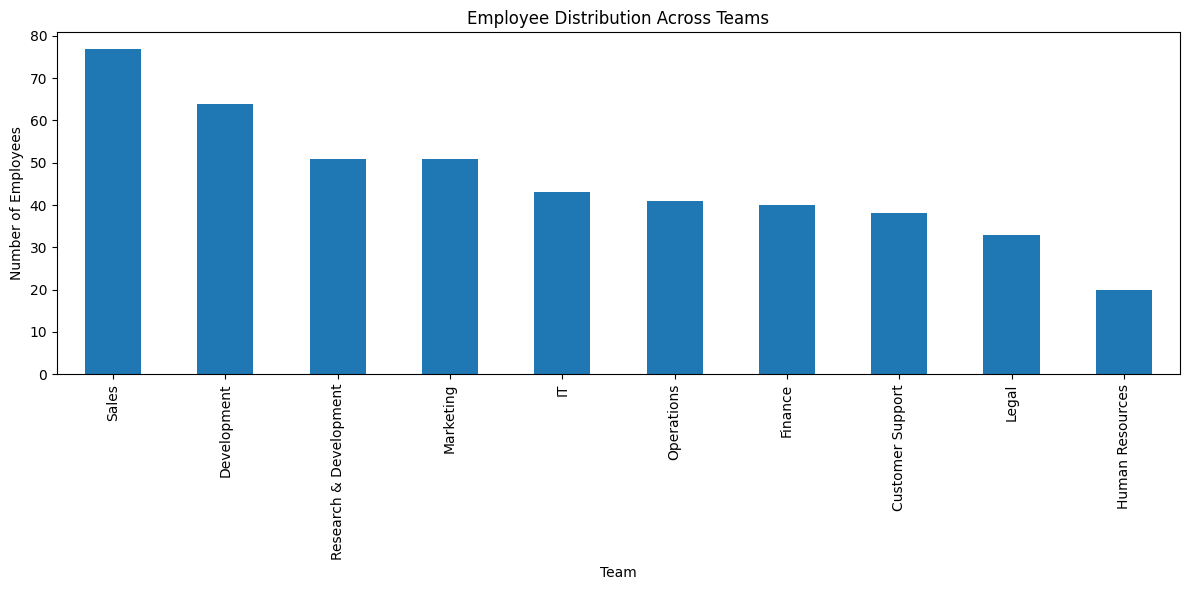

In [8]:
team_count = df["Team"].value_counts()
team_percentage = df["Team"].value_counts(normalize=True) * 100

team_summary = pd.DataFrame({
    "Employee Count": team_count,
    "Percentage": team_percentage
})

print(team_summary)

team_count.plot(kind="bar", figsize=(12, 6))
plt.title("Employee Distribution Across Teams")
plt.xlabel("Team")
plt.ylabel("Number of Employees")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

3. Employee segregation by position

Position
Associate    127
Junior       114
Senior        96
Manager       66
Intern        33
Director      22
Name: count, dtype: int64


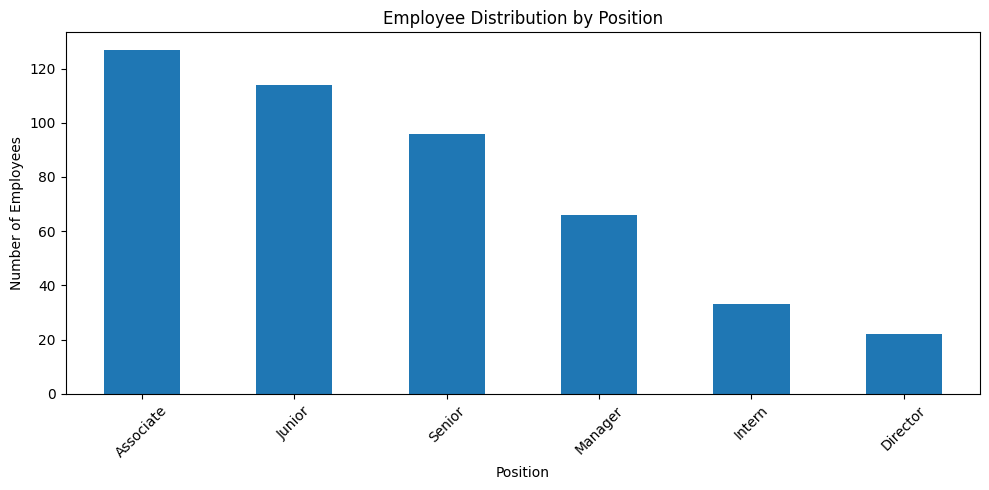

In [9]:
position_count = df["Position"].value_counts()

print(position_count)

position_count.plot(kind="bar", figsize=(10, 5))
plt.title("Employee Distribution by Position")
plt.xlabel("Position")
plt.ylabel("Number of Employees")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

4. Predominant age group
Group employees into age ranges and identify the age group with the highest number of employees.

Age Group
Below 20     10
20-29        98
30-39       227
40-49       108
50-59        15
Name: count, dtype: int64


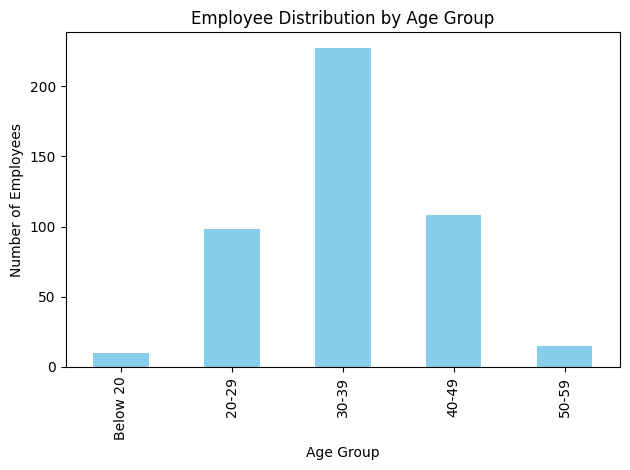

In [10]:
bins = [0, 20, 30, 40, 50, 60]
labels = ["Below 20", "20-29", "30-39", "40-49", "50-59"]

df["Age Group"] = pd.cut(
    df["Age"],
    bins=bins,
    labels=labels,
    right=False
)

age_count = df["Age Group"].value_counts().sort_index()

print(age_count)

age_count.plot(kind="bar", color="skyblue")
plt.title("Employee Distribution by Age Group")
plt.xlabel("Age Group")
plt.ylabel("Number of Employees")
plt.tight_layout()
plt.show()

5. Team and position with the highest salary expenditure

Use the total salary expenditure rather than the average salary.

Salary expenditure by team:
Team
Sales                     5046900
Development               4399500
Research & Development    3710800
Marketing                 3375400
IT                        3129400
Finance                   2904300
Operations                2755700
Customer Support          2640800
Legal                     1800300
Human Resources           1126200
Name: Salary, dtype: int64

Salary expenditure by position:
Position
Associate    7549500
Senior       7525800
Manager      6720600
Junior       5180700
Director     2925300
Intern        987400
Name: Salary, dtype: int64


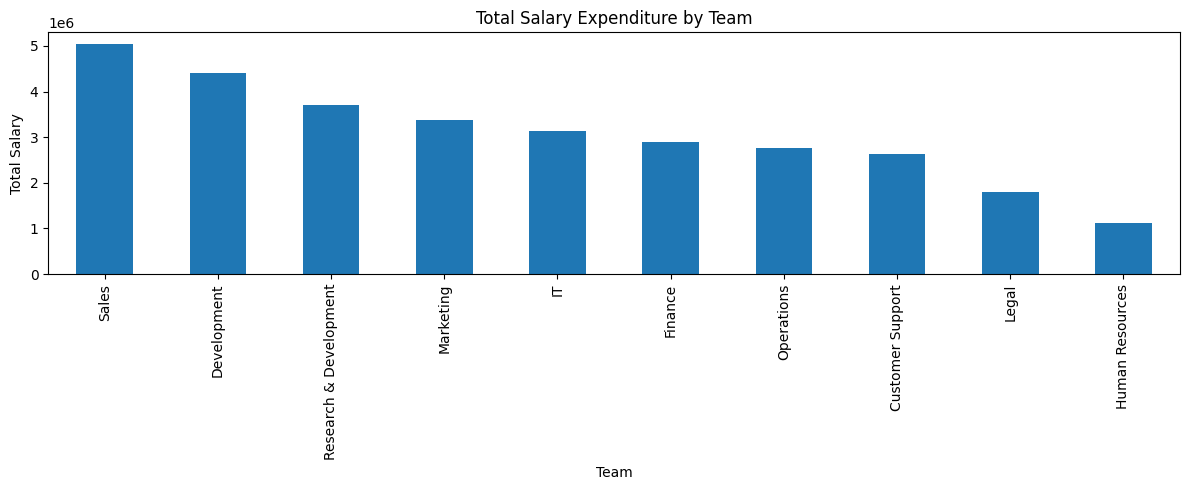

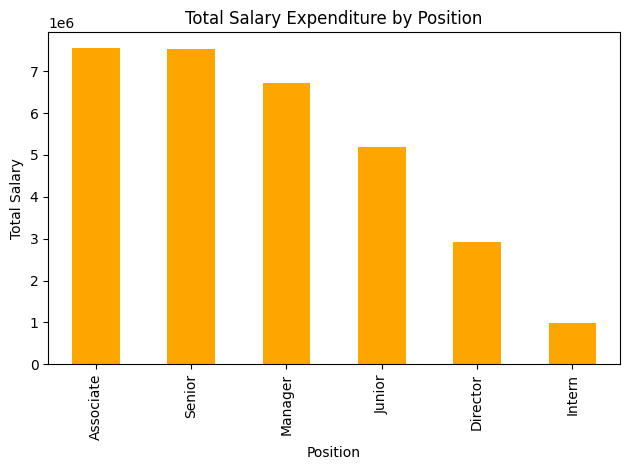

In [11]:
team_salary = df.groupby("Team")["Salary"].sum().sort_values(
    ascending=False
)

position_salary = df.groupby("Position")["Salary"].sum().sort_values(
    ascending=False
)

print("Salary expenditure by team:")
print(team_salary)

print("\nSalary expenditure by position:")
print(position_salary)

team_salary.plot(kind="bar", figsize=(12, 5))
plt.title("Total Salary Expenditure by Team")
plt.xlabel("Team")
plt.ylabel("Total Salary")
plt.xticks(rotation=90)
plt.tight_layout()
plt.show()

position_salary.plot(kind="bar", color="orange")
plt.title("Total Salary Expenditure by Position")
plt.xlabel("Position")
plt.ylabel("Total Salary")
plt.tight_layout()
plt.show()

6.Correlation between age and salary
Calculate the Pearson correlation coefficient and visualize the relationship using a scatter plot with a regression line.

Correlation between Age and Salary: 0.1560087412159291


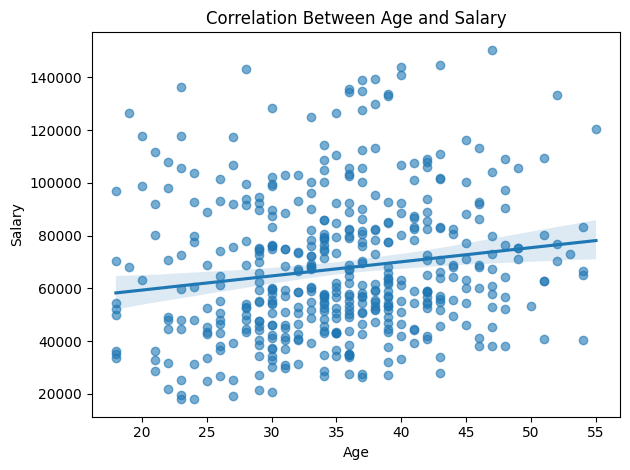

In [12]:
correlation = df["Age"].corr(df["Salary"])

print("Correlation between Age and Salary:", correlation)

sns.regplot(
    data=df,
    x="Age",
    y="Salary",
    scatter_kws={"alpha": 0.6}
)

plt.title("Correlation Between Age and Salary")
plt.xlabel("Age")
plt.ylabel("Salary")
plt.tight_layout()
plt.show()

Near +1: strong positive linear correlation.



Near -1: strong negative linear correlation.



Near 0: weak or no linear correlation.